# 05 · Event-related activity and uncertainty

## Goal
Distinguish evoked voltage from changes in oscillatory power, retain participant/run/trial identity, and estimate uncertainty at the correct level.

**Scope:** a reproducible teaching analysis of public recordings, not clinical validation. Downloaded data are cached locally; no synthetic fallback is used. Each notebook runs independently.

## Setup
Use the environment in `README.md`. The default sample is deliberately small; results are descriptive unless explicitly stated otherwise.

In [2]:
from pathlib import Path
import sys
course_dir = Path.cwd() if (Path.cwd() / 'course_utils.py').exists() else Path.cwd() / 'EEG_from_ground_up'
assert (course_dir / 'course_utils.py').exists(), 'Open this notebook from the course folder or project root.'
sys.path.insert(0, str(course_dir.resolve()))
from course_utils import ROOT, DATA, OUTPUT, SEED, load_run, versions, style, save_table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from IPython.display import display
%matplotlib inline
style()
rng = np.random.default_rng(SEED)
display(versions().to_frame())

,version
numpy,2.5.4
scipy,1.18.1
pandas,3.0.6
matplotlib,3.11.2
mne,1.13.2
moabb,1.7.2
pyriemann,0.12
braindecode,1.8.1
torch,2.14.1
scikit-learn,1.9.1


## Steps

### 1. Build a trial collection with provenance
Use participants 1–3 and imagery runs 4, 8, 12. These are repeated runs, not established separate-day sessions. Each run is filtered independently at 1–40 Hz and average-referenced. This descriptive analysis does not use an adaptive artifact model. Inspect the QC limitations before interpreting effects.

The −2 to +4 s epochs provide wavelet padding. Cue timing anchors the analysis; the internal onset of imagery is not observed.

In [4]:
SUBJECTS=[1,2,3]; RUNS=[4,8,12]
collections=[]
for subject in SUBJECTS:
    for run in RUNS:
        r=load_run(subject,run).set_eeg_reference('average',projection=False,verbose=False)
        r.filter(1,40,verbose=False)
        ev,_=mne.events_from_annotations(r,event_id={'T1':1,'T2':2},verbose=False)
        meta=pd.DataFrame({'subject':subject,'run':run,'trial':np.arange(len(ev)),
            'condition':np.where(ev[:,2]==1,'left','right')})
        e=mne.Epochs(r,ev,event_id={'left':1,'right':2},tmin=-2,tmax=4,baseline=None,
            picks=['C3','C4'],metadata=meta,preload=True,verbose=False)
        collections.append(e)
epochs=mne.concatenate_epochs(collections,verbose=False)
meta=epochs.metadata.reset_index(drop=True)
display(meta.groupby(['subject','run','condition']).size().unstack(fill_value=0))
print('Retained trials:',len(epochs),'Unique participants:',meta.subject.nunique())

/Users/trush/Documents/Research/Synaptrix/synaptrixmotorimagerydata/EEG_from_ground_up/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/kf/_m2km__d5bb0zspsmwn5gvdh0000gn/T/ipykernel_23056/1322430839.py:13: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs=mne.concatenate_epochs(collections,verbose=False)


condition    left  right
subject run             
1       4       8      7
        8       8      7
        12      7      8
2       4       7      8
        8       8      7
        12      8      7
3       4       8      7
        8       7      8
        12      8      7

Retained trials: 135 Unique participants: 3


Retained trials: 135 Unique participants: 3


### 2. Evoked voltage versus induced power
An event-related average retains activity consistently phase-aligned to the event. Averaging voltage can cancel an oscillation whose phase varies across trials; averaging its power does not. The curves below are cue-locked averages, not a validated motor-specific ERP. The 1 Hz high-pass also limits interpretation of slow potentials.

Average within each participant first, then weight participants equally. This avoids giving participants with more retained trials greater group weight.

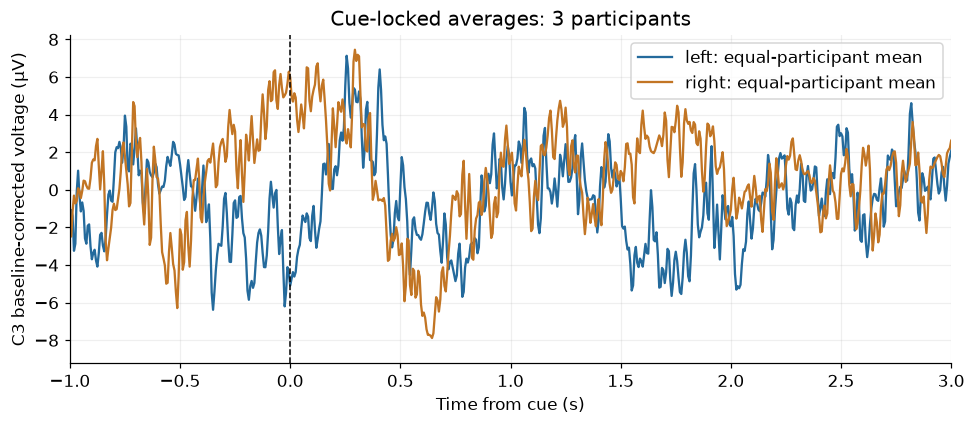

In [8]:
voltage=epochs.copy().apply_baseline((-.8,-.2)).get_data()*1e6
time=epochs.times
fig,ax=plt.subplots()
for label in ['left','right']:
    curves=np.stack([voltage[(meta.subject==s)&(meta.condition==label),0].mean(axis=0) for s in SUBJECTS])
    ax.plot(time,curves.mean(axis=0),label=f'{label}: equal-participant mean')
ax.axvline(0,color='black',ls='--',lw=1)
ax.set(xlim=(-1,3),xlabel='Time from cue (s)',ylabel='C3 baseline-corrected voltage (µV)',title='Cue-locked averages: 3 participants')
ax.legend(); plt.tight_layout(); plt.show()

### 3. Define an effect before estimating it
Use mu-band frequencies 8–12 Hz, baseline −1.5 to −0.5 s, and task interval +0.5 to +2.5 s. These fixed teaching choices are not optimized on significance.

For each trial and channel, define D=10 log₁₀(P_task/P_baseline). Negative D indicates a power decrease. Define lateralization L=D_C3−D_C4 and the participant contrast L_left−L_right. This signed contrast is descriptive; it is not by itself evidence of a particular neural generator.

In [10]:
fs=epochs.info['sfreq']; freqs=np.arange(8,13)
power=mne.time_frequency.tfr_array_morlet(epochs.get_data(),sfreq=fs,freqs=freqs,
    n_cycles=4,output='power',decim=4,n_jobs=1,verbose=False)
t=epochs.times[::4]; base=(t>=-1.5)&(t<=-.5); active=(t>=.5)&(t<=2.5)
pbase=power[...,base].mean(axis=(-1,-2)); ptask=power[...,active].mean(axis=(-1,-2))
effect=10*np.log10(ptask/pbase)
trials=meta.copy(); trials['C3_change_dB']=effect[:,0]; trials['C4_change_dB']=effect[:,1]
trials['lateralization_dB']=effect[:,0]-effect[:,1]
save_table(trials,'05_trial_effects.csv')
# First average trials within run, then runs within participant and condition.
run_effects=trials.groupby(['subject','run','condition']).lateralization_dB.mean()
participant=run_effects.groupby(['subject','condition']).mean().unstack()
participant['left_minus_right_dB']=participant['left']-participant['right']
display(save_table(participant.reset_index(),'05_participant_effects.csv'))

condition,subject,left,right,left_minus_right_dB
0,1,-0.693074,-1.847051,1.153977
1,2,-1.057202,-1.782505,0.725303
2,3,-0.730204,0.534619,-1.264823


### 4. Participant-level uncertainty
Resample participants, not time samples or overlapping windows. With only three participants, a percentile bootstrap has very limited support and may be unstable. The interval is a teaching demonstration, not a reliable population claim. Trial-to-trial variability and between-person variability answer different questions.
The unit of replication follows the question. For an individual’s trial-to-trial reliability, trials or blocks may be relevant. For inference to a population, independently sampled participants are the relevant units. Thousands of correlated time samples do not turn three participants into a large population sample. The bootstrap here weights the three observed participants equally and does not establish representativeness.

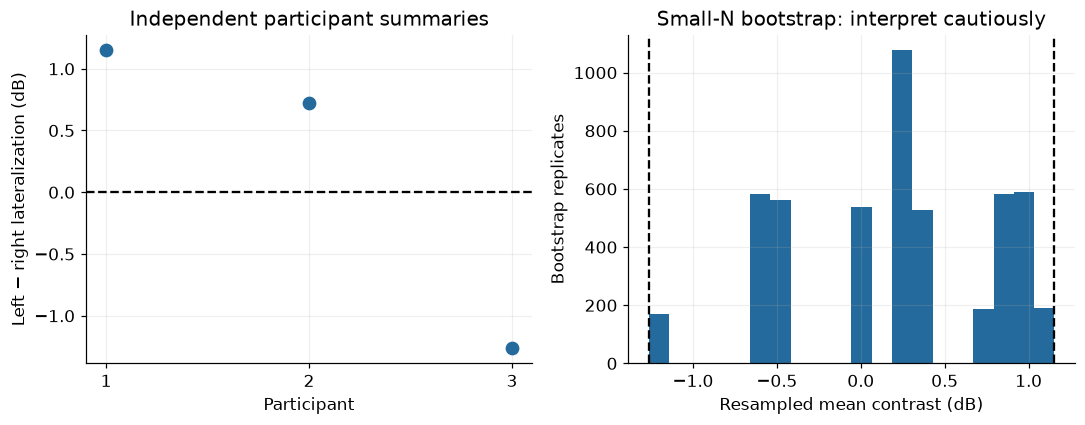

Mean contrast = 0.205 dB; illustrative 95% percentile interval [-1.265, 1.154], N=3.


In [12]:
d=participant.left_minus_right_dB.to_numpy()
boot=rng.choice(d,size=(5000,len(d)),replace=True).mean(axis=1)
lo,hi=np.percentile(boot,[2.5,97.5])
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(participant.index,d,'o',ms=8)
axes[0].axhline(0,color='black',ls='--'); axes[0].set(xticks=SUBJECTS,xlabel='Participant',ylabel='Left − right lateralization (dB)',title='Independent participant summaries')
axes[1].hist(boot,bins=20,color='#246a9c'); axes[1].axvline(lo,color='black',ls='--'); axes[1].axvline(hi,color='black',ls='--')
axes[1].set(xlabel='Resampled mean contrast (dB)',ylabel='Bootstrap replicates',title='Small-N bootstrap: interpret cautiously')
plt.tight_layout(); plt.show()
print(f'Mean contrast = {d.mean():.3f} dB; illustrative 95% percentile interval [{lo:.3f}, {hi:.3f}], N={len(d)}.')

### 5. An exact small-sample null illustration
A sign-flip test assumes independent participant effects symmetric around zero under the null. Enumerate all 2ᴺ signs. With N=3, two-sided inference is extremely coarse. This is an explicit statistical assumption, not something guaranteed by the recording design. Scanning many channels/frequencies/times would additionally require multiplicity control.

In [14]:
from itertools import product
signs=np.array(list(product([-1,1],repeat=len(d))))
null=(signs*d).mean(axis=1)
p_exact=np.mean(np.abs(null)>=abs(d.mean())-1e-12)
print(f'Exact two-sided sign-flip p={p_exact:.3f} from {len(null)} sign patterns.')

Exact two-sided sign-flip p=1.000 from 8 sign patterns.


## Checks

In [16]:
assert len(meta)==len(effect)
assert not meta.duplicated(['subject','run','trial']).any()
assert np.isfinite(effect).all() and len(participant)==len(SUBJECTS)
print('Trial provenance and participant-level aggregation verified.')

Trial provenance and participant-level aggregation verified.


## Next Steps
Notebook 06 asks a different question: whether unseen runs can be classified. A descriptive difference need not yield useful prediction, and predictive accuracy does not establish mechanism.

**Exercises:** calculate a within-participant interval by resampling whole runs; explain why it cannot substitute for a population interval. Expand the participant list before making population claims. Treat frequency-band changes as sensitivity analyses, not opportunities to choose the smallest p-value.

## Sources and further reading
Original teaching code; the resources below provide APIs, methodological guidance, and dataset provenance. No tutorial text or full external notebook is reproduced.

- [PhysioNet dataset and protocol](https://physionet.org/content/eegmmidb/1.0.0/)
- [MNE ERD/ERS](https://mne.tools/stable/auto_examples/time_frequency/time_frequency_erds.html)
- [MNE statistical inference](https://mne.tools/stable/auto_tutorials/stats-sensor-space/10_background_stats.html)